<a href="https://colab.research.google.com/github/roaaats-maker/Breast-Cancer-ML/blob/main/breast_canser_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Introduction

## 1. Problem Definition
Breast cancer is one of the most common cancers among women, and detecting it early greatly improves the chances of successful treatment. A key step in diagnosis is deciding whether a breast mass is benign (non-cancerous) or malignant (cancerous). In this project, we treat this decision as a binary classification problem: given measurements of a cell sample, predict whether the tumor is benign or malignant.

## 2. Dataset
We use the Breast Cancer Wisconsin (Diagnostic) dataset, available on Kaggle. It contains 569 samples, each describing a breast mass. The features were computed from digitized images of a fine needle aspirate (FNA) of the mass and describe the characteristics of the cell nuclei. Ten measurements (such as radius, texture, perimeter, area, smoothness and concavity) are given in three versions: the mean, the standard error and the "worst" (largest) value, giving 30 numeric features in total. The target variable is the diagnosis: 357 samples are benign (B) and 212 are malignant (M).

## 3. Objectives
The goals of this project are:
- To clean and prepare the data and explore it to understand which features separate benign from malignant tumors.
- To build and compare traditional machine learning models (Logistic Regression and Random Forest) using a proper train/validation/test split and cross-validation.
- To build a Neural Network, tune its hyperparameters, and analyze its training and validation curves for overfitting and underfitting.
- To evaluate all models on the test set with suitable metrics and discuss which model performs best and why.

## 4. Evaluation Considerations
Because the dataset is slightly imbalanced (about 63% benign and 37% malignant) and missing a malignant case is more serious than a false alarm, we do not rely on accuracy alone. Recall, precision and F1-score are also used when comparing the models.

## 5. Structure of the Report
The rest of the report is organized as follows: Stage 1 covers data cleaning, preparation and exploratory data analysis; Stage 2 covers data splitting and the traditional models; Stages 3 and 4 cover the Neural Network and its tuning; Stage 5 presents the evaluation on the test set, followed by a discussion and conclusion. The code is available in our GitHub repository: https://github.com/roaaats-maker/Breast-Cancer-ML

#Stage 1: Data Cleaning, Preparation & EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1.1 Loading the Data

In [2]:
df = pd.read_csv("data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 1.2 Understanding the Data

In [3]:
print(df.shape)
df.info()

(569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se    

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [5]:
df['diagnosis'].value_counts()

,count
diagnosis,
B,357
M,212


The dataset has 569 rows and 33 columns. The target variable is diagnosis (M = malignant, B = benign). All 30 features are numeric measurements of cell nuclei, in addition to an id column. There is a column called Unnamed: 32 that contains only missing values.

## 1.3 Data Cleaning

In [6]:
df.isnull().sum().sort_values(ascending=False).head()

,0
Unnamed: 32,569
id,0
diagnosis,0
texture_mean,0
radius_mean,0


In [7]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df.shape

(569, 31)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
df['diagnosis'].value_counts()

,count
diagnosis,
0,357
1,212


The column Unnamed: 32 contained only missing values, so it was removed. The id column is only an identifier and has no predictive value, so it was also dropped. No duplicate rows were found. The target diagnosis was encoded as M = 1 (malignant) and B = 0 (benign), giving 212 malignant and 357 benign cases.

## 1.4 Outliers


In [10]:
features = df.drop(columns='diagnosis').columns
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[features] < Q1 - 1.5*IQR) | (df[features] > Q3 + 1.5*IQR)).sum()
outliers.sort_values(ascending=False).head(10)

,0
area_se,65
radius_se,38
perimeter_se,38
area_worst,35
smoothness_se,30
fractal_dimension_se,28
compactness_se,28
symmetry_se,27
area_mean,25
fractal_dimension_worst,24


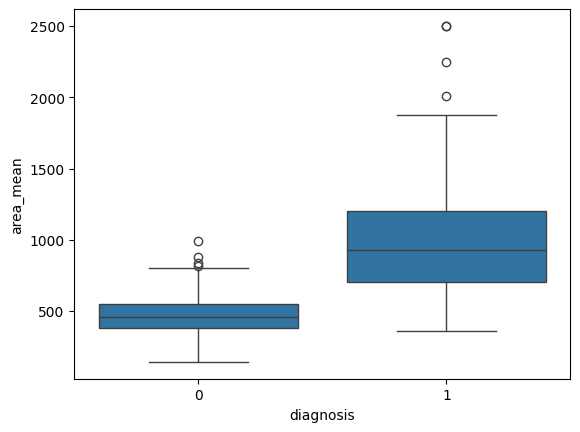

In [11]:
sns.boxplot(x='diagnosis', y='area_mean', data=df)
plt.show()

The IQR method showed outliers in many features, with area_se having the most (65 values). However, these outliers were not removed, because the dataset is small (569 rows) and the extreme values mostly belong to malignant tumors, so they carry useful information rather than being errors. The boxplot of area_mean confirms this: malignant tumors have a higher median (about 930 vs. 450) and the most extreme values (above 2000). Instead of removing them, feature scaling will be applied later to reduce their effect.

## 1.5 Exploratory Data Analysis (EDA)

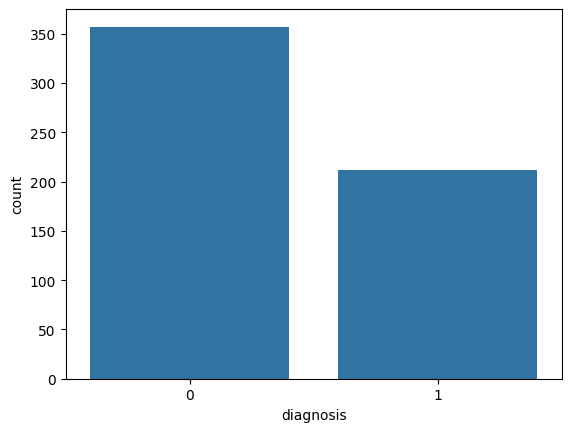

diagnosis
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [12]:
sns.countplot(x='diagnosis', data=df)
plt.show()
print(df['diagnosis'].value_counts(normalize=True))

The target variable is slightly imbalanced: 62.7% of the cases are benign (357) and 37.3% are malignant (212). The imbalance is mild, so no resampling is needed, but accuracy alone may be misleading. Therefore, recall, precision and F1-score will also be used when evaluating the models, since missing a malignant case is more costly than a false alarm.

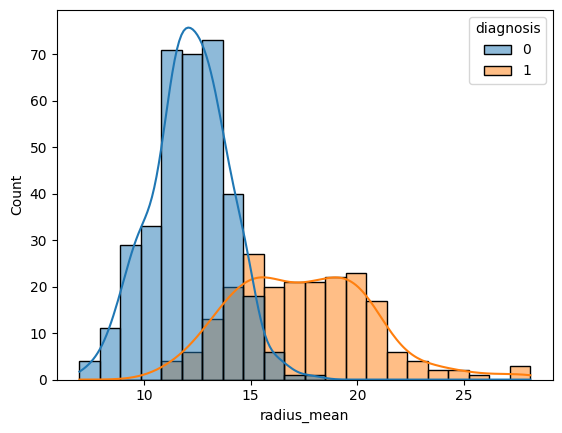

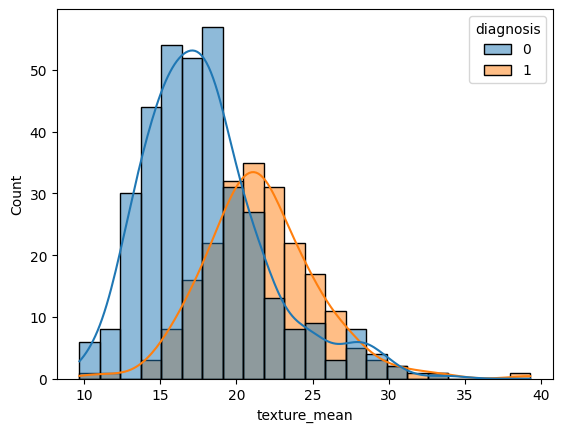

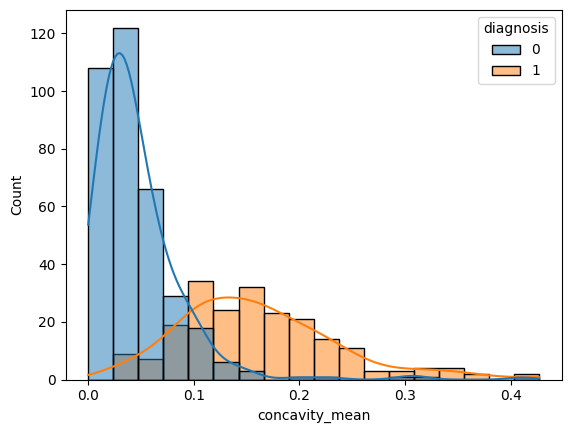

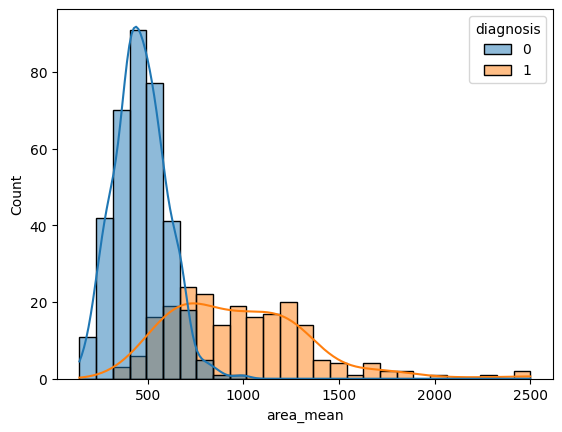

In [13]:
for col in ['radius_mean', 'texture_mean', 'concavity_mean', 'area_mean']:
    sns.histplot(data=df, x=col, hue='diagnosis', kde=True)
    plt.show()

The histograms show that malignant tumors tend to have higher values than benign ones in radius_mean, area_mean and concavity_mean. For example, benign tumors are concentrated around a radius of 12 and an area of 500, while malignant tumors are centered around a radius of 18-20 and have a wider range of areas. Concavity is close to zero for most benign cases but higher for malignant ones. In contrast, texture_mean shows a large overlap between the two classes, so it is a weaker feature for separating them. Most distributions are right-skewed.


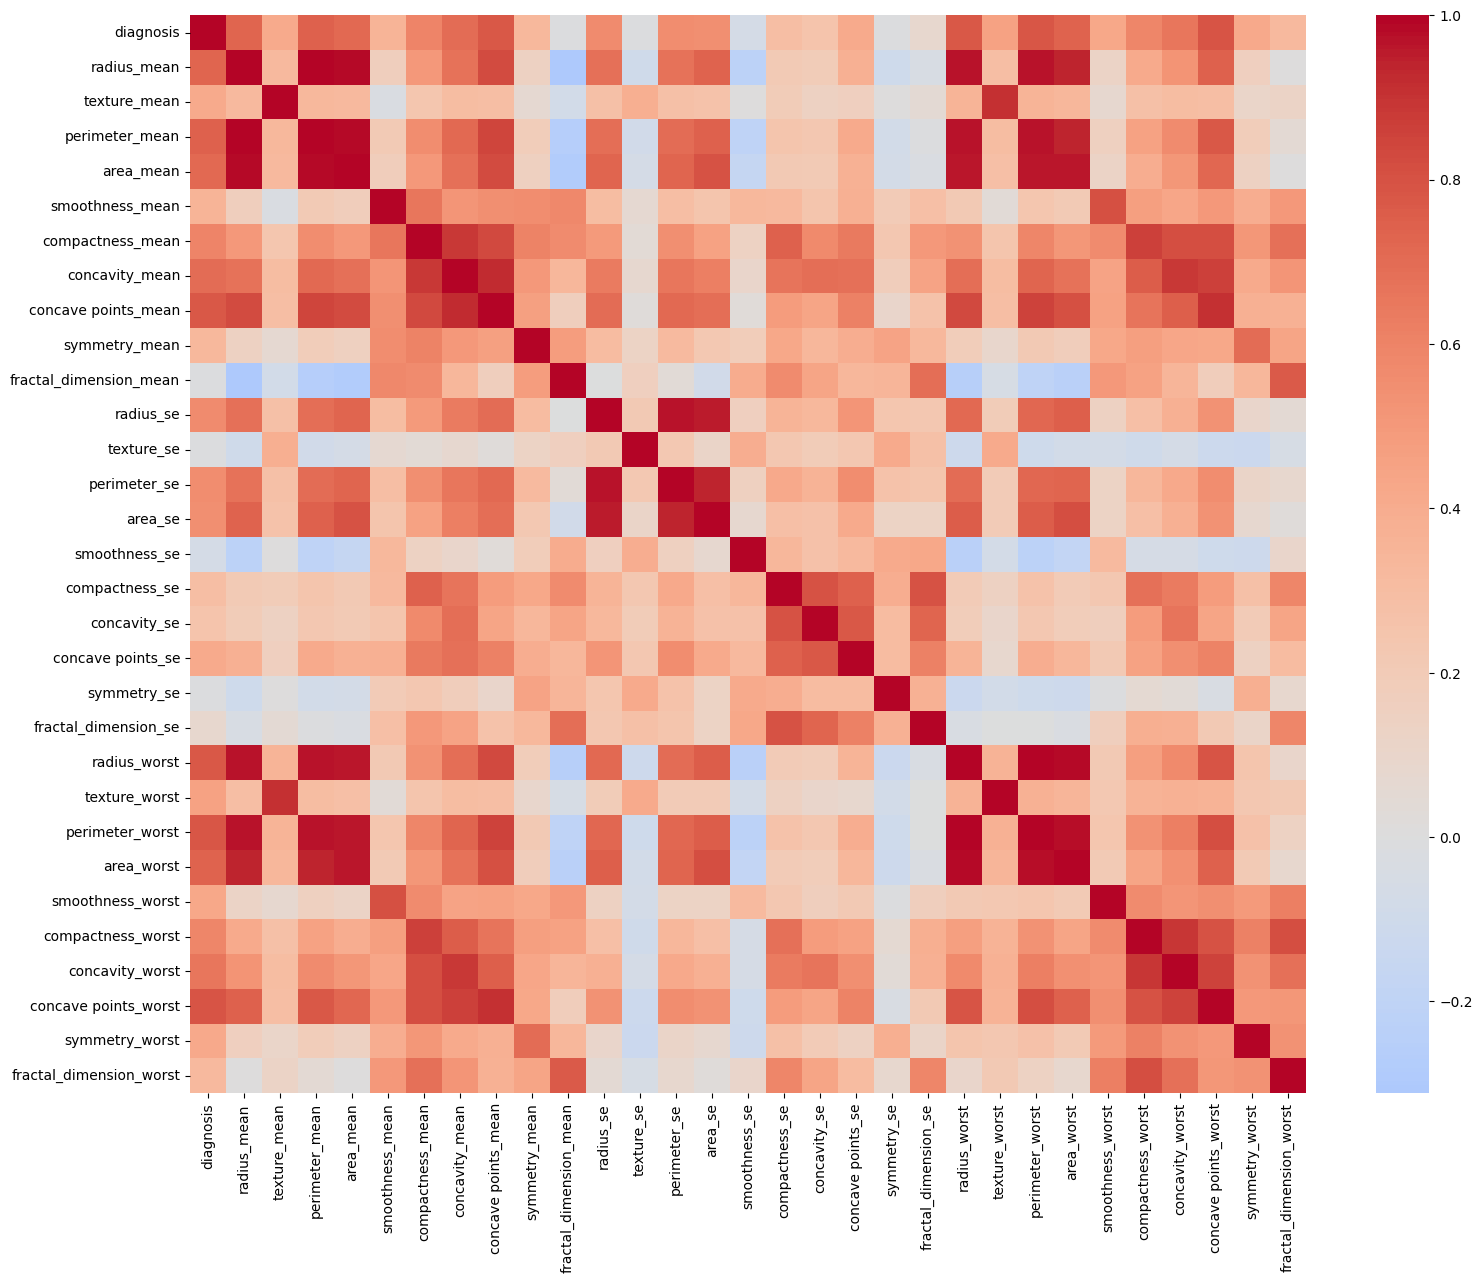

In [14]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.show()

In [15]:
df.corr()['diagnosis'].drop('diagnosis').sort_values(ascending=False)

,diagnosis
concave points_worst,0.793566
perimeter_worst,0.782914
concave points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


The correlation heatmap shows that radius, perimeter and area (in their mean and worst versions) are almost perfectly correlated with each other, which means they carry nearly the same information (multicollinearity). The features most correlated with the diagnosis are concave points_worst (0.79), perimeter_worst (0.78), concave points_mean (0.78) and radius_worst (0.78), while fractal_dimension_mean, texture_se, symmetry_se and smoothness_se have almost no correlation with it (close to 0). This suggests that some features are redundant and others are not useful, so feature selection is needed.

## 1.6 Feature Selection

In [17]:
corr = df.drop(columns='diagnosis').corr().abs()
target_corr = df.corr()['diagnosis'].abs()
cols = corr.columns

to_drop = set()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if corr.iloc[i, j] > 0.9:
            a, b = cols[i], cols[j]
            to_drop.add(a if target_corr[a] < target_corr[b] else b)

print(len(to_drop))
print(sorted(to_drop))

10
['area_mean', 'area_se', 'area_worst', 'concave points_mean', 'concavity_mean', 'perimeter_mean', 'perimeter_se', 'radius_mean', 'radius_worst', 'texture_mean']


In [18]:
df_selected = df.drop(columns=list(to_drop))
print(df_selected.shape)
print(list(df_selected.columns))

(569, 21)
['diagnosis', 'smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'texture_worst', 'perimeter_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


To reduce multicollinearity, we looked for pairs of features with a correlation higher than 0.9. In each pair, the feature with the weaker correlation with the diagnosis was removed and the stronger one was kept. This removed 10 features (such as radius_mean, area_mean, perimeter_mean and concave points_mean), while stronger representatives such as perimeter_worst and concave points_worst were kept. The result is a reduced dataset of 20 features, which lowers redundancy and should make the models simpler and more stable.

### Feature importance check (Random Forest)


perimeter_worst            0.251244
concave points_worst       0.249918
concavity_worst            0.116975
radius_se                  0.069511
compactness_mean           0.042628
compactness_worst          0.039565
texture_worst              0.033414
concavity_se               0.032783
fractal_dimension_mean     0.022065
concave points_se          0.018645
smoothness_worst           0.017084
symmetry_worst             0.014828
compactness_se             0.014570
smoothness_mean            0.013421
fractal_dimension_worst    0.012972
fractal_dimension_se       0.011278
smoothness_se              0.010335
symmetry_se                0.010282
symmetry_mean              0.010021
texture_se                 0.008462
dtype: float64


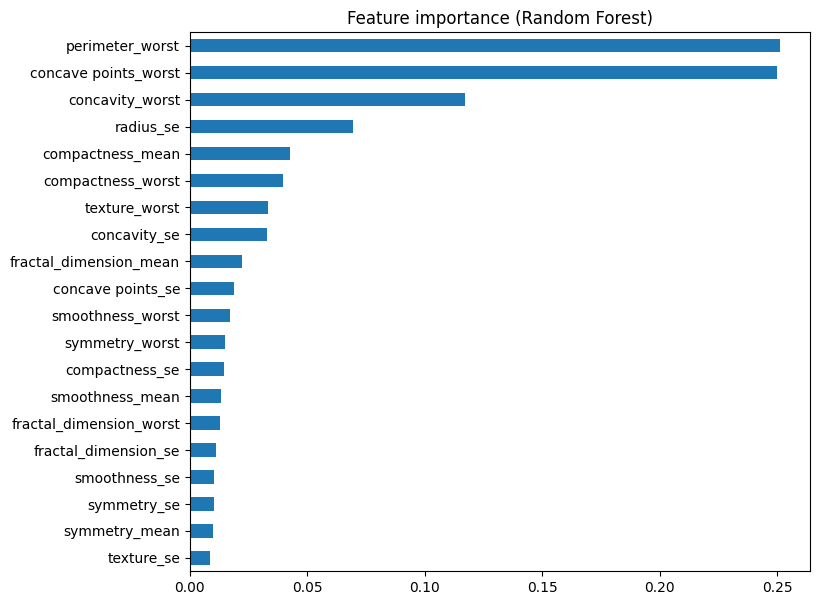

In [19]:
from sklearn.ensemble import RandomForestClassifier

X = df_selected.drop(columns='diagnosis')
y = df_selected['diagnosis']

rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances)

importances.sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Feature importance (Random Forest)')
plt.show()


A Random Forest was used to check the importance of the remaining 20 features. The most important ones are perimeter_worst (0.25), concave points_worst (0.25) and concavity_worst (0.12), which agrees with the correlation analysis. Features such as texture_se, symmetry_mean and symmetry_se have very low importance (about 0.01). Since the dataset is small and the correlated features were already removed, we kept all 20 features as the final set, so that the models can decide which ones are useful. This check was done only for exploration and the real model training is done after splitting the data.

In [20]:
df_selected.to_csv("data_clean.csv", index=False)

#Stage 2: Data Splitting & Traditional Models

#Stage 3: Neural Network

#Stage 4: Neural Network Tuning & Curves

#Stage 5: Evaluation on Test Set


#Discussion

#Conclusion